# AI-generated files and their maintenance
**Paper:** Sawada et al. 2026 – To What Extent Does Agent-generated Code Require Maintenance?
**Data:** https://github.com/ShouSawa/AI-Code-Maintainability

**What is in the data:** Files **created by AI agents** and files created by humans in 100 repositories (from AIDev), and every later commit on them, labelled with Conventional Commits types (**fix**, feat, refactor, docs…).

**One row of the main table =** one later commit on one file

This notebook has 3 parts:
1. **First look** – the files, some lines, all the columns, the size.
2. **Data-science view** – size, dates, **numbers per AI agent**, **how the agent is involved** (tables saved in `tables/`).
3. **Charts** – what kind of change · fixes per AI agent · who wrote the fix · how fast the fix comes · extra (saved in `charts/`).

In [1]:
import sys, os, json
sys.path.insert(0, "..")          # to find common.py in the parent folder
from common import *

## 0. Get the data

In [2]:
root = get_repo("https://github.com/ShouSawa/AI-Code-Maintainability", "ai-code-maintainability")

Data folder: ../../data/03_Sawada/ai-code-maintainability


## 1. First look
### Files in the repository

In [3]:
list_files(root)

,file,size_MB
0,dataset/analyze-dataset/dataset_AI_commits.csv,6.08
1,results/EASE-results/csv/results_v7_released_commits_res...,1.00


### Main table: later commits on AI and human files (`results_v7`, the paper's final table)

In [4]:
m = pd.read_csv(os.path.join(root, "results", "EASE-results", "csv", "results_v7_released_commits_restriction.csv"))
_ = overview(m, "Later commits on files")

**Later commits on files** — **4,338 rows × 14 columns** (1.4 MB in memory)

*First 5 lines:*

,repository_name,file_name,file_creators,file_created_by,file_line_count,file_creation_date,file_commit_count,commit_hash,commit_authors,commit_created_by,commit_changed_lines,commit_date,commit_classification,file_specific_changed_lines
0,microsoft/vscode,src/vs/editor/test/common/languages/defaultDocumentColor...,"Copilot, GitHub",AI,102,2025-06-16T17:23:18+00:00,2,24c0ff16c250f2b39eea8cebd661be2375f61ba5,"Copilot, GitHub",AI,104,2025-06-16T17:23:18+00:00,fix,102
1,microsoft/vscode,src/vs/editor/test/common/languages/defaultDocumentColor...,"Copilot, GitHub",AI,102,2025-06-16T17:23:18+00:00,2,6aeb5973b6c6c3c6f207ebf35536f7377f1e66df,Matt Bierner,Human,26374,2025-10-15T17:06:36+00:00,fix,8
2,microsoft/vscode,src/vs/editor/test/common/languages/defaultDocumentColor...,"Copilot, GitHub",AI,102,2025-06-16T17:23:18+00:00,2,a8f4b34cfe00be0875b6f51f3fed718f72cf0c0e,"Igor, GitHub",Human,25,2025-12-16T14:30:43+00:00,test,21
3,microsoft/vscode,src/vs/editor/test/common/languages/defaultDocumentColor...,"Copilot, GitHub",AI,102,2025-06-16T17:23:18+00:00,2,192dcc20ec2c36f44a67e2ed1dd33dda622418e0,Dmitriy Vasyura,Human,55,2025-12-19T11:21:25+00:00,test,48
4,microsoft/vscode,src/vs/editor/test/common/languages/defaultDocumentColor...,"Copilot, GitHub",AI,102,2025-06-16T17:23:18+00:00,2,47acb9091c2e118ccce5e38d27c9a0deba9d16fe,Dmitriy Vasyura,Human,26,2025-12-19T11:25:40+00:00,test,20


*All columns:*

,column,type,missing_%,unique,example
0,repository_name,str,0.0,100,microsoft/vscode
1,file_name,str,0.0,1011,src/vs/editor/test/common/languages/defaultDocumen
2,file_creators,str,0.0,299,"Copilot, GitHub"
3,file_created_by,str,0.0,2,AI
4,file_line_count,int64,0.0,326,102
5,file_creation_date,str,0.0,707,2025-06-16T17:23:18+00:00
6,file_commit_count,int64,0.0,36,2
7,commit_hash,str,0.0,3231,24c0ff16c250f2b39eea8cebd661be2375f61ba5
8,commit_authors,str,0.0,619,"Copilot, GitHub"
9,commit_created_by,str,0.0,2,AI


### Second table: all commits of the repositories, AI or not

In [5]:
c = pd.read_csv(os.path.join(root, "dataset", "analyze-dataset", "dataset_AI_commits.csv"))
_ = overview(c, "All commits")

**All commits** — **49,547 rows × 7 columns** (8.3 MB in memory)

*First 5 lines:*

,repository,commit_sha,author_name,all_authors,commit_date,is_ai,ai_tool
0,TheAlgorithms/Python,f662b63d1ad958d6f14a25136979f3ebdabb987a,dependabot[bot],"dependabot[bot], GitHub",2025-08-12 07:30:10,Human,NaN
1,TheAlgorithms/Python,d05f5d22d92424f1197950d519fc7a2059de4a5a,pre-commit-ci[bot],"pre-commit-ci[bot], GitHub",2025-08-11 19:03:20,Human,NaN
2,TheAlgorithms/Python,7a0fee401d2990bd5904e94cd5d3a62c50a8b682,pre-commit-ci[bot],"pre-commit-ci[bot], GitHub",2025-07-29 21:27:27,Human,NaN
3,TheAlgorithms/Python,6e1a1048774468ab2d7717ceae34b43f005dce2d,pre-commit-ci[bot],"pre-commit-ci[bot], GitHub",2025-07-21 19:29:24,Human,NaN
4,TheAlgorithms/Python,d1a9486f09f47a14ea6bfdfcfaf61c0297476d84,pre-commit-ci[bot],"pre-commit-ci[bot], GitHub",2025-07-11 21:06:49,Human,NaN


*All columns:*

,column,type,missing_%,unique,example
0,repository,str,0.0,100,TheAlgorithms/Python
1,commit_sha,str,0.0,49547,f662b63d1ad958d6f14a25136979f3ebdabb987a
2,author_name,str,0.0,6144,dependabot[bot]
3,all_authors,str,0.0,6604,"dependabot[bot], GitHub"
4,commit_date,str,0.0,49127,2025-08-12 07:30:10
5,is_ai,str,0.0,2,Human
6,ai_tool,str,99.3,4,GitHub Copilot


## 2. Data-science view
### Size and dates

In [6]:
m["agent"] = m.apply(lambda r: agent_of(r["file_creators"]) if r["file_created_by"] == "AI" else "Human file", axis=1)
m["commit_date"] = pd.to_datetime(m["commit_date"], utc=True, errors="coerce")
m["file_creation_date"] = pd.to_datetime(m["file_creation_date"], utc=True, errors="coerce")
m["days_after_creation"] = (m["commit_date"] - m["file_creation_date"]).dt.days
print("Rows (commit x file):", len(m), "| repos:", m.repository_name.nunique(), "| files:", m.file_name.nunique(), "| commits:", m.commit_hash.nunique())
print("Files created by AI :", m[m.file_created_by == "AI"].file_name.nunique(), "| by humans:", m[m.file_created_by == "Human"].file_name.nunique())
print("Dates of commits    :", m.commit_date.min().date(), "->", m.commit_date.max().date())

Rows (commit x file): 4338 | repos: 100 | files: 1011 | commits: 3231
Files created by AI : 504 | by humans: 508
Dates of commits    : 2021-10-14 -> 2026-02-16


### Numbers per AI agent (the agent that created the file)

In [7]:
fx = m[m.commit_classification == "fix"]
per_agent = m.groupby("agent").agg(files=("file_name", "nunique"), later_commits=("commit_hash", "nunique"))
fxu = fx.drop_duplicates(["agent", "commit_hash"])   # one row per fix commit
per_agent = per_agent.join(fxu.groupby("agent").agg(fix_commits=("commit_hash", "nunique"),
            fix_by_human=("commit_created_by", lambda s: (s == "Human").sum()), fix_by_AI=("commit_created_by", lambda s: (s == "AI").sum()),
            median_days_to_fix=("days_after_creation", "median")))
per_agent["fix_%_of_later_commits"] = (100 * per_agent["fix_commits"] / per_agent["later_commits"]).round(1)
per_agent = per_agent.sort_values("files", ascending=False)
save_table(per_agent.reset_index(), "per_agent")
per_agent

,files,later_commits,fix_commits,fix_by_human,fix_by_AI,median_days_to_fix,fix_%_of_later_commits
agent,,,,,,,
Human file,508,1922,298,286,12,32.0,15.5
Copilot,260,467,80,26,54,0.0,17.1
Devin,174,492,83,70,13,78.0,16.9
Cursor,39,262,37,32,5,7.0,14.1
Claude Code,17,60,6,2,4,0.0,10.0
Human / other,14,140,10,9,1,143.5,7.1


### How the agent is involved
The agent **creates the file** (`file_creators`, e.g. `devin-ai-integration[bot]`). Later commits are made by a **human or an AI** (`commit_created_by`).

In [8]:
inv = pd.crosstab(m["file_created_by"], m["commit_created_by"], margins=True)
save_table(inv.reset_index(), "who_changes_files")
inv

commit_created_by,AI,Human,All
file_created_by,,,
AI,755,1337,2092
Human,125,2121,2246
All,880,3458,4338


In [9]:
summary_card("Sawada et al. 2026", "later commit on a file", len(m), m.repository_name.nunique(), str(m.commit_date.min().date()),
             str(m.commit_date.max().date()), ", ".join(sorted(set(m.agent) - {"Human file"})), "Agent creates files; later commits by humans or AI",
             int(fx[fx.file_created_by == "AI"].commit_hash.nunique()))

,
paper,Sawada et al. 2026
unit (1 row =),later commit on a file
rows,4338
repos,100
first date,2021-10-14
latest date,2026-02-16
agents,"Claude Code, Copilot, Cursor, Devin, Human / other"
how the agent is involved,Agent creates files; later commits by humans or AI
fixes of AI code,216


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Sawada et al. 2026,later commit on a file,4338,100,2021-10-14,2026-02-16,"Claude Code, Copilot, Cursor, Devin, Human / other",Agent creates files; later commits by humans or AI,216


## 3. Charts
### Chart 1 · What kind of later change (AI files vs human files)

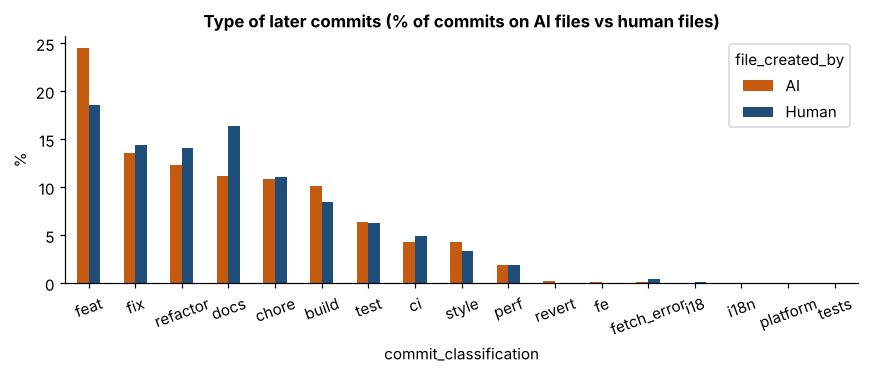

In [10]:
k = pd.crosstab(m["commit_classification"], m["file_created_by"], normalize="columns").mul(100).round(1).sort_values("AI", ascending=False)
save_table(k.reset_index(), "change_type_pct")
fig, ax = plt.subplots(figsize=(8, 3.5)); k.plot(kind="bar", ax=ax, color=[ORANGE, BLUE])
ax.set_title("Type of later commits (% of commits on AI files vs human files)"); ax.set_ylabel("%"); plt.xticks(rotation=20)
save_chart(fig, "1_change_types.png")

### Chart 2 · Fix commits per AI agent

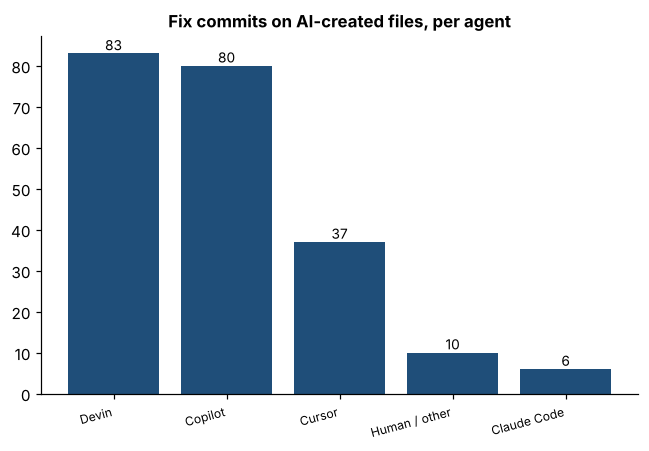

*Exact numbers – Fix commits on AI-created files, per agent*

,number,%
agent,,
Devin,83.0,38.4
Copilot,80.0,37.0
Cursor,37.0,17.1
Human / other,10.0,4.6
Claude Code,6.0,2.8
TOTAL,216.0,100.0


In [11]:
bar(fx[fx.file_created_by == "AI"].drop_duplicates("commit_hash")["agent"].value_counts(), "Fix commits on AI-created files, per agent", "2_fixes_per_agent.png", horizontal=True)

### Chart 3 · Who wrote the fix

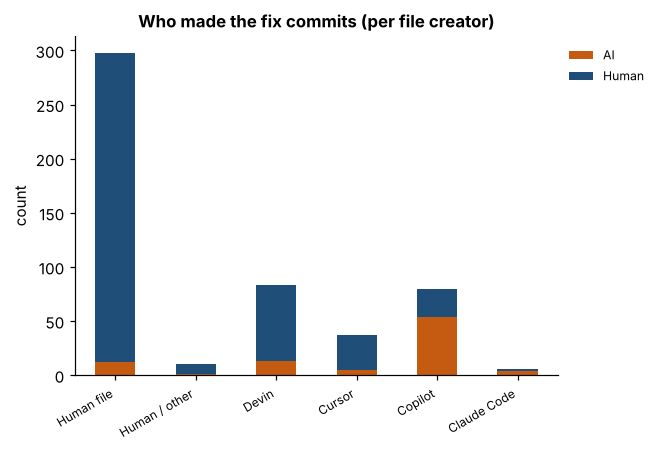

*Exact numbers – Who made the fix commits (per file creator)*

commit_created_by,AI,Human,TOTAL
agent,,,
Claude Code,4,2,6
Copilot,54,26,80
Cursor,5,32,37
Devin,13,70,83
Human / other,1,9,10
Human file,12,286,298
TOTAL,89,425,514


In [12]:
stacked(pd.crosstab(fxu["agent"], fxu["commit_created_by"]), "Who made the fix commits (per file creator)", "3_who_fixes.png", colors=[ORANGE, BLUE])

### Chart 4 · How fast the fix comes

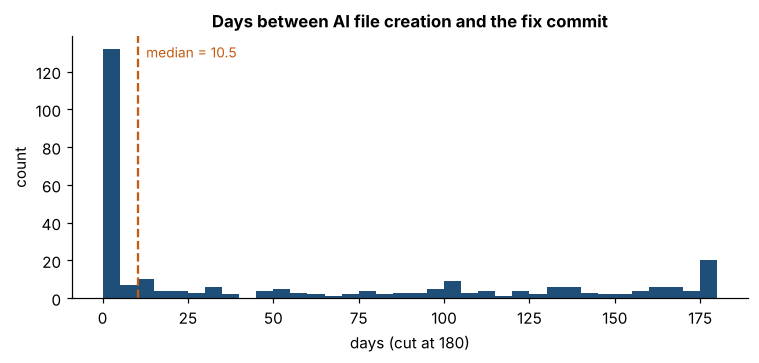

*Exact numbers – Days between AI file creation and the fix commit*

,count,mean,std,min,25%,median,75%,max
days (cut at 180),284.0,53.7,65.82,0.0,0.0,10.5,106.25,180.0


In [13]:
hist(fx[fx.file_created_by == "AI"]["days_after_creation"].clip(upper=180), "Days between AI file creation and the fix commit", "4_days_to_fix.png", "days (cut at 180)", bins=36)

### Extra · AI commits per tool in all the commits of the repositories

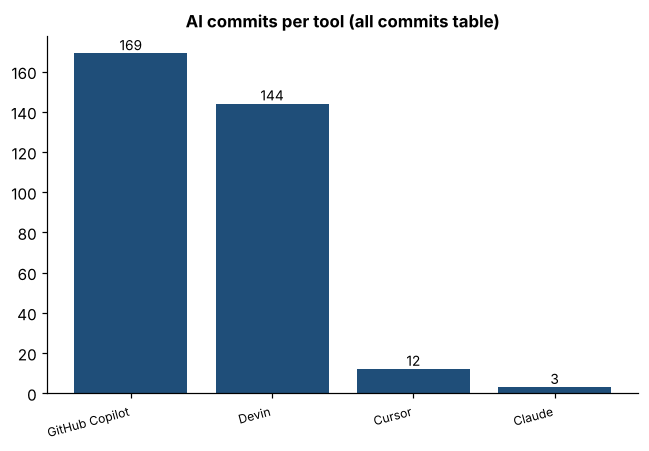

*Exact numbers – AI commits per tool (all commits table)*

,number,%
ai_tool,,
GitHub Copilot,169.0,51.5
Devin,144.0,43.9
Cursor,12.0,3.7
Claude,3.0,0.9
TOTAL,328.0,100.0


In [14]:
bar(c[c.is_ai == "AI"]["ai_tool"].value_counts(), "AI commits per tool (all commits table)", "5_ai_commits_per_tool.png", horizontal=True)

## 4. Final figure (the 4 charts on one page)

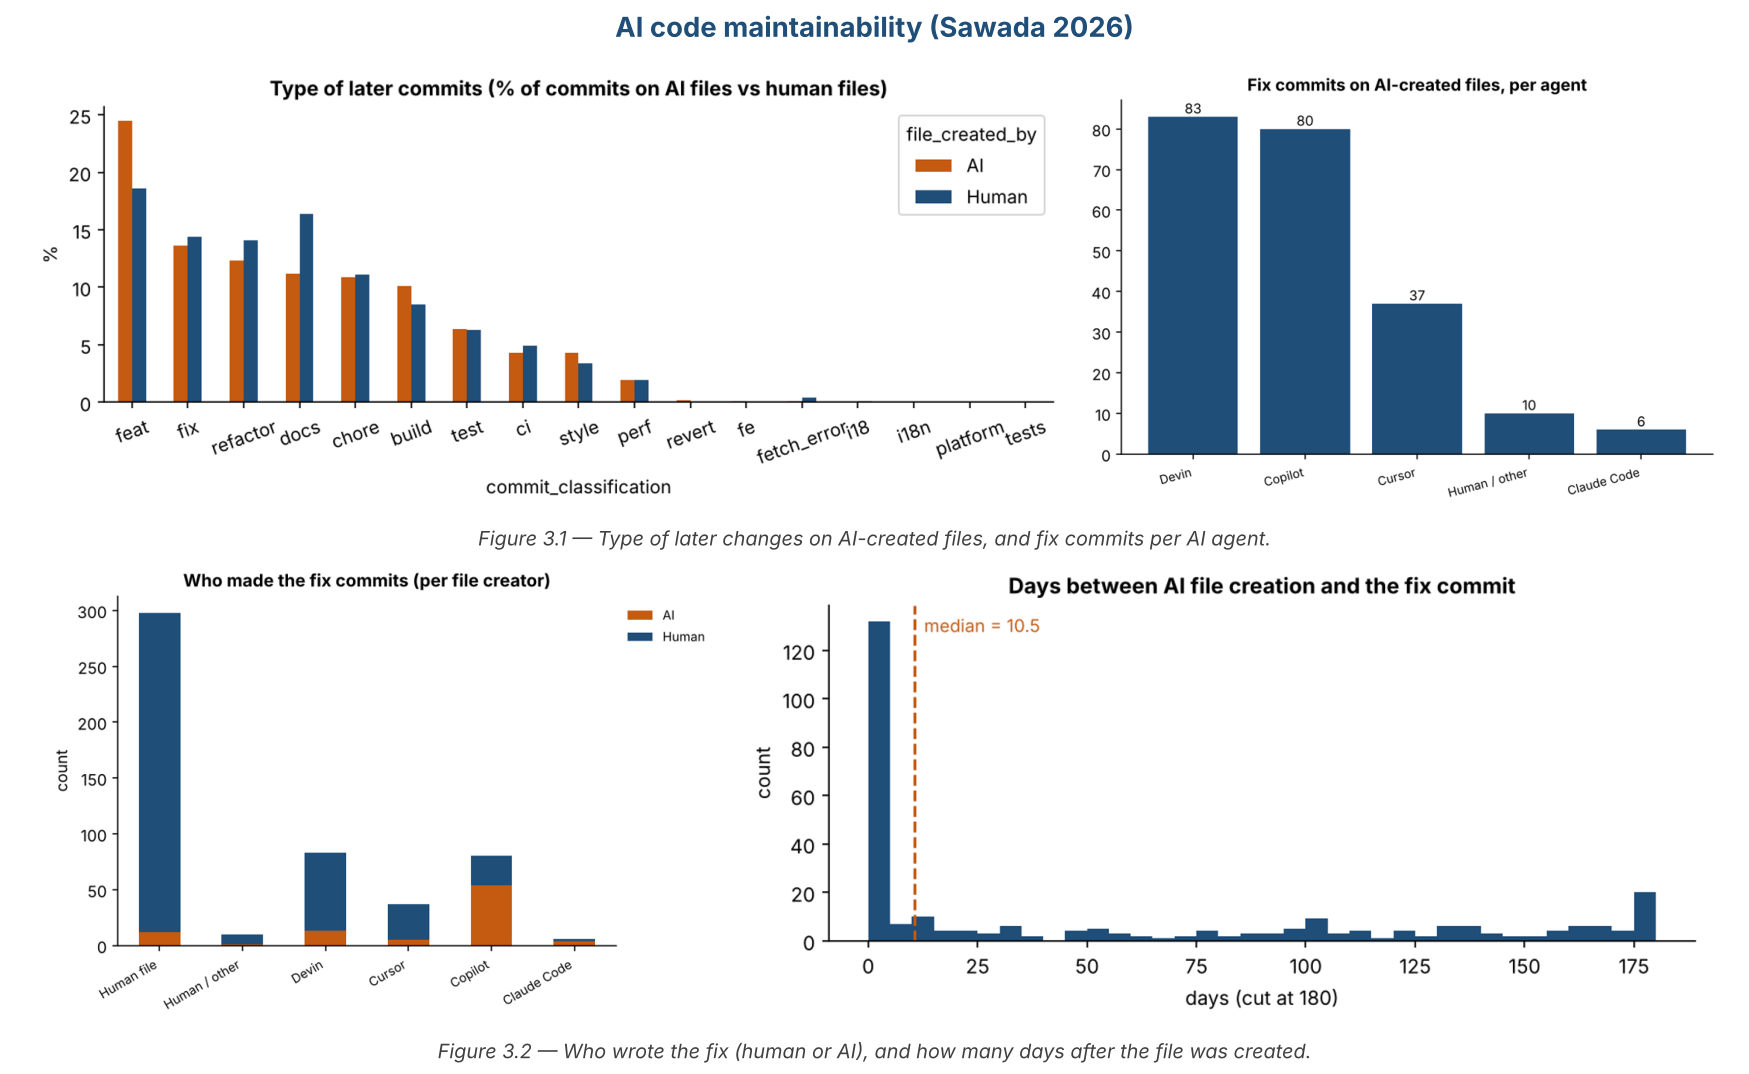

In [15]:
final_figure(3, "AI code maintainability (Sawada 2026)",
             "Type of later changes on AI-created files, and fix commits per AI agent.",
             "Who wrote the fix (human or AI), and how many days after the file was created.")

## 5. The fixes in one common format
Each row = one **fix commit on a file created by an AI agent**.

The notebook `99_ALL_PAPERS_summary` merges this file from every paper into the **final dataset**.

In [16]:
a = fx[fx.file_created_by == "AI"]
g = a.groupby(["agent", "repository_name", "commit_hash"], as_index=False).agg(
    files=("file_name", list), who=("commit_created_by", "first"), days=("days_after_creation", "min"))
f = pd.DataFrame({"agent": g["agent"], "repo": g["repository_name"], "language": g["files"].map(lang_of), "level": "commit",
    "ai_change": "file created by AI", "fix_change": g["commit_hash"],
    "fixed_by": g["who"].map({"Human": "Human", "AI": "AI agent"}).fillna("Unknown"), "days_to_fix": g["days"],
    "fix_label": "fix (Conventional Commits)", "fix_reason": None, "has_code_patch": False})
fixes = save_fixes(f, "Sawada 2026")

**216 fixes saved to `tables/fixes.csv`** (same columns in every paper)

,paper,fix_id,agent,repo,language,level,ai_change,fix_change,fixed_by,days_to_fix,fix_label,fix_reason,has_code_patch
0,Sawada 2026,SAW-00000,Claude Code,MervinPraison/PraisonAI,Python,commit,file created by AI,e5ee0c793ece67ad34e6c5d0bd0d2782e74cc2f5,AI agent,0,fix (Conventional Commits),None,False
1,Sawada 2026,SAW-00001,Claude Code,browser-use/browser-use,Python,commit,file created by AI,fba94602febecab17864e406380d8a08df34c4bb,AI agent,0,fix (Conventional Commits),None,False
2,Sawada 2026,SAW-00002,Claude Code,elizaOS/eliza,TypeScript,commit,file created by AI,257fda58c86e076fa0e684b97ede8b2207b39171,AI agent,0,fix (Conventional Commits),None,False
3,Sawada 2026,SAW-00003,Claude Code,liam-hq/liam,Other,commit,file created by AI,8f9f70cd88b528bd6dfc5ef49682cfb2283b1eda,AI agent,0,fix (Conventional Commits),None,False
4,Sawada 2026,SAW-00004,Claude Code,yamadashy/repomix,TypeScript,commit,file created by AI,3384d667c2ebe80a09d09c16b7ed8154ba6e9f2b,Human,16,fix (Conventional Commits),None,False
